In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [35]:
df = pd.read_csv("diamonds_price_prediction.csv")
df

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
...,...,...,...,...,...,...,...,...,...,...,...
53935,53936,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,53937,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,53938,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,53939,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74


In [36]:
df.head()

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [37]:
df.tail()

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
53935,53936,0.72,Ideal,D,SI1,60.8,57.0,2757,5.75,5.76,3.50
53936,53937,0.72,Good,D,SI1,63.1,55.0,2757,5.69,5.75,3.61
53937,53938,0.70,Very Good,D,SI1,62.8,60.0,2757,5.66,5.68,3.56
53938,53939,0.86,Premium,H,SI2,61.0,58.0,2757,6.15,6.12,3.74
53939,53940,0.75,Ideal,D,SI2,62.2,55.0,2757,5.83,5.87,3.64


In [38]:
print(df.shape)

(53940, 11)


In [39]:
print(df.columns)

Index(['Unnamed: 0', 'carat', 'cut', 'color', 'clarity', 'depth', 'table',
       'price', 'x', 'y', 'z'],
      dtype='object')


In [40]:
df.dtypes

Unnamed: 0      int64
carat         float64
cut            object
color          object
clarity        object
depth         float64
table         float64
price           int64
x             float64
y             float64
z             float64
dtype: object

In [41]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  object 
 3   color       53940 non-null  object 
 4   clarity     53940 non-null  object 
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), object(3)
memory usage: 4.5+ MB


In [42]:
df.describe()

,Unnamed: 0,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,26970.500000,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,15571.281097,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,1.000000,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,13485.750000,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,26970.500000,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,40455.250000,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,53940.000000,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [43]:
df.drop('Unnamed: 0', axis=1, inplace=True)

In [44]:
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [45]:
df.shape

(53940, 10)

In [53]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns

In [54]:
print(numeric_cols)
print(categorical_cols)

Index(['carat', 'depth', 'table', 'price', 'Length', 'Width', 'Height'], dtype='object')
Index(['cut', 'color', 'clarity'], dtype='object')


In [48]:
df.rename(columns={'x': 'Length'}, inplace=True)
df.rename(columns={'y': 'Width'}, inplace=True)
df.rename(columns={'z': 'Height'}, inplace=True)

In [49]:
df.head()

,carat,cut,color,clarity,depth,table,price,Length,Width,Height
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [50]:
target = df['price']

In [51]:
print(df.isnull().sum())

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
Length     0
Width      0
Height     0
dtype: int64


In [52]:
print(df.duplicated().sum())

146


In [56]:
df.drop_duplicates(inplace=True)
df.shape

(53794, 10)

In [59]:
# Find rows with length, breadth, height = 0 
zero_rows = df[(df['Length'] == 0) | (df['Width'] == 0) | (df['Height'] == 0)]
print(len(zero_rows))

19


In [60]:
df = df.drop(zero_rows.index)
df = df.reset_index(drop=True)
print(df.shape)

(53775, 10)


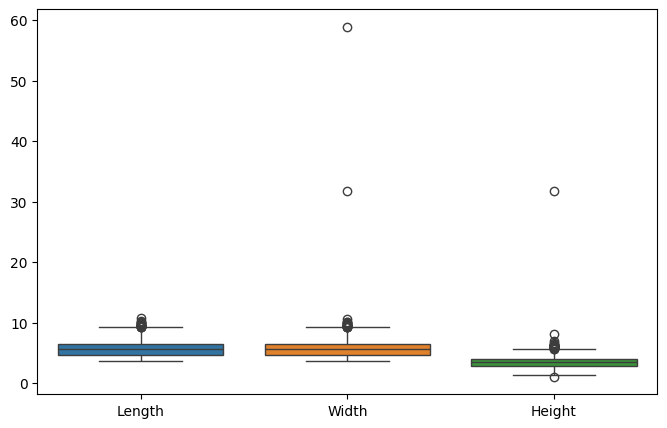

In [65]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df[['Length', 'Width', 'Height']])
plt.show()

In [67]:
# There are no outliers in Length
df[(df['Width'] > 12) | (df['Height'] > 12)]

,carat,cut,color,clarity,depth,table,price,Length,Width,Height
24003,2.00,Premium,H,SI2,58.9,57.0,12210,8.09,58.90,8.06
48251,0.51,Very Good,E,VS1,61.8,54.7,1970,5.12,5.15,31.80
49030,0.51,Ideal,E,VS1,61.8,55.0,2075,5.15,31.80,5.12


In [68]:
df = df[(df['Width'] < 12) & (df['Height'] < 12)]
df = df.reset_index(drop=True)
print(df.shape)

(53772, 10)


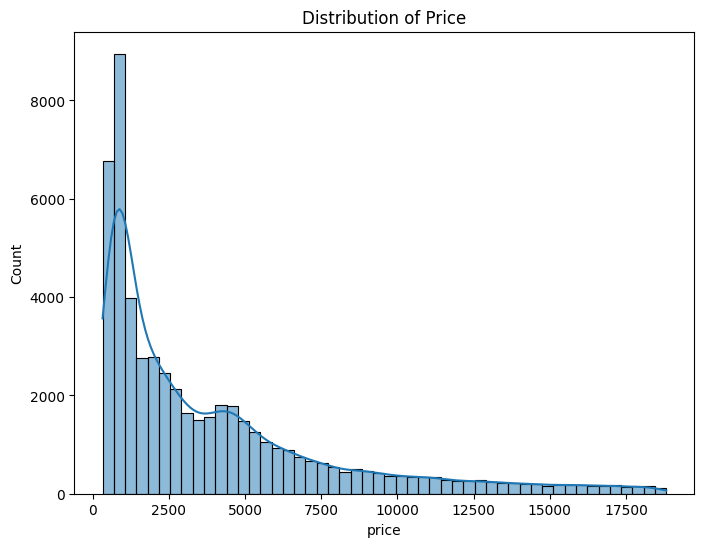

In [70]:
plt.figure(figsize=(8, 6))
sns.histplot(df['price'], bins=50, kde=True)
plt.title('Distribution of Price')
plt.show()

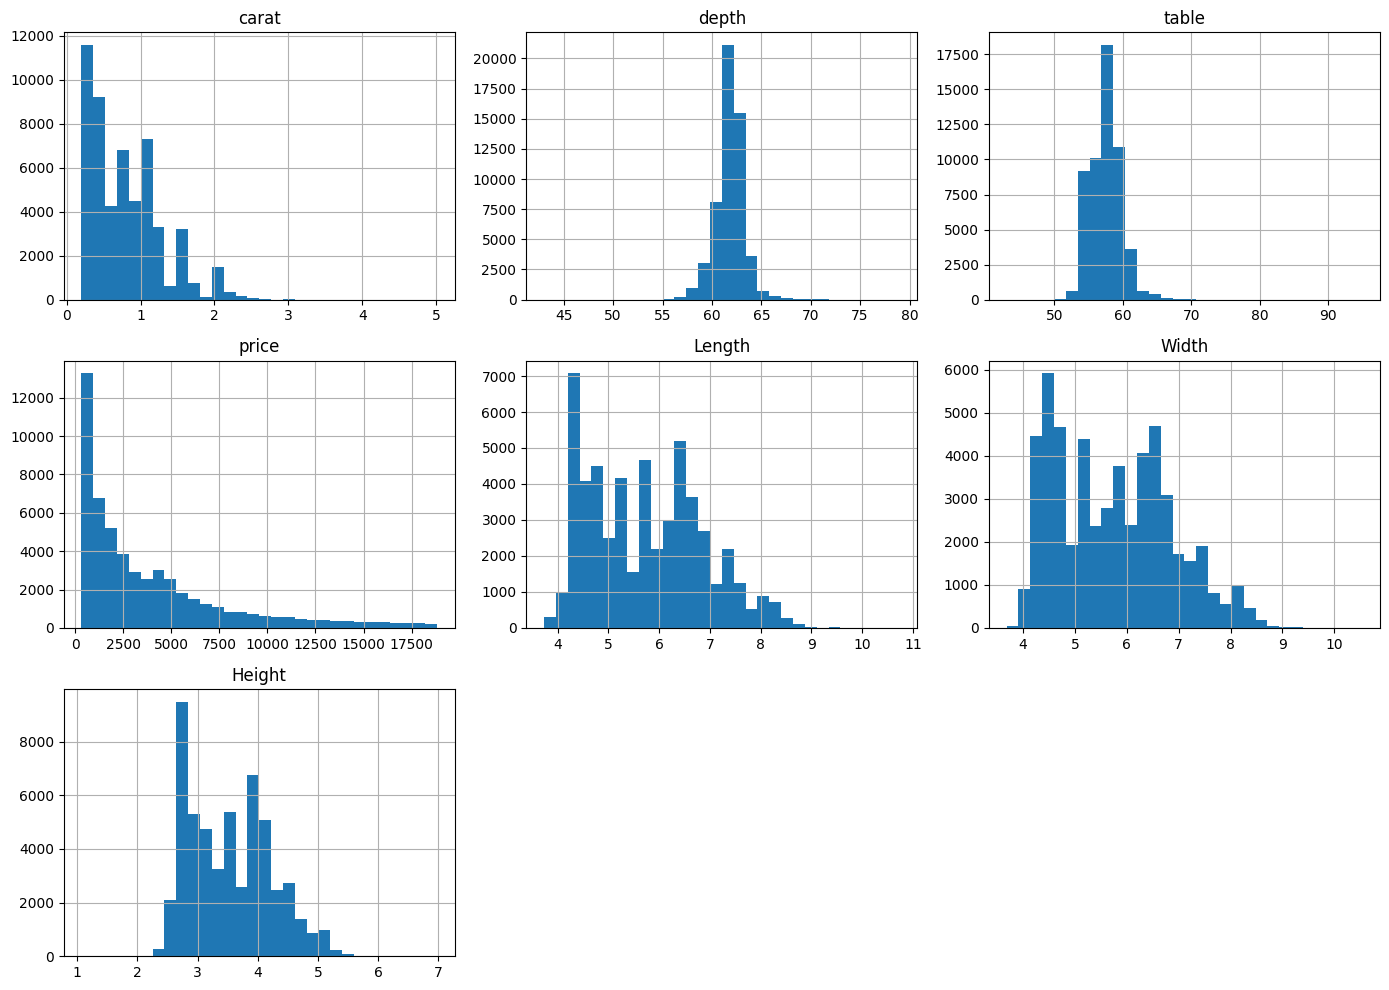

In [78]:
df[numeric_cols].hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

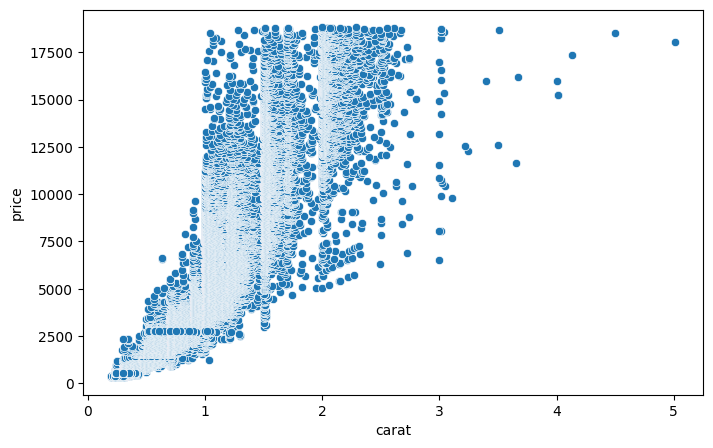

In [75]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='carat', y='price', data=df)
plt.show()

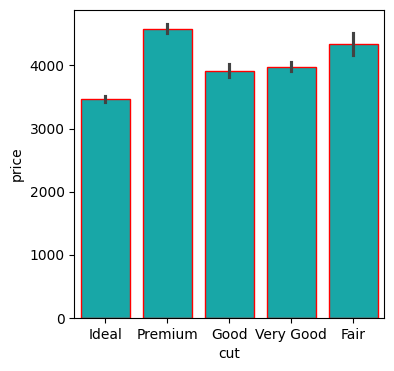

In [86]:
plt.figure(figsize=(4, 4))
sns.barplot(x='cut', y='price', data=df, color='c', edgecolor='r')
plt.show()

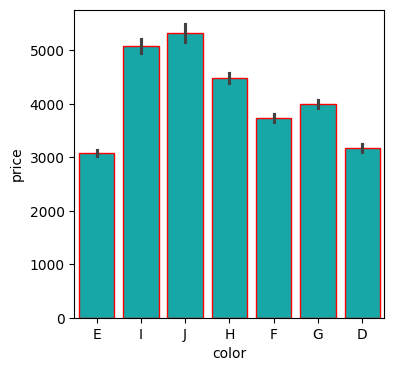

In [87]:
plt.figure(figsize=(4, 4))
sns.barplot(x='color', y='price', data=df, color='c', edgecolor='r')
plt.show()


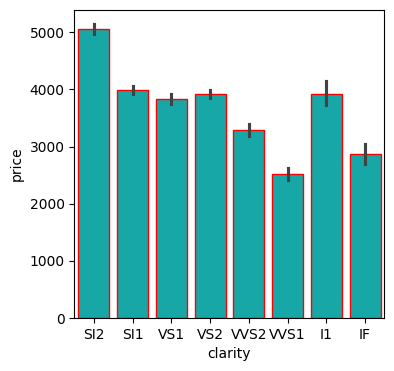

In [88]:
plt.figure(figsize=(4, 4))
sns.barplot(x='clarity', y='price', data=df, color='c', edgecolor='r')
plt.show()

In [90]:
df.corr(numeric_only=True)

,carat,depth,table,price,Length,Width,Height
carat,1.000000,0.027987,0.181113,0.921542,0.977856,0.976940,0.976527
depth,0.027987,1.000000,-0.297604,-0.011067,-0.025147,-0.028268,0.096397
table,0.181113,-0.297604,1.000000,0.126662,0.195450,0.189267,0.155105
price,0.921542,-0.011067,0.126662,1.000000,0.887127,0.888718,0.881986
Length,0.977856,-0.025147,0.195450,0.887127,1.000000,0.998654,0.991090
Width,0.976940,-0.028268,0.189267,0.888718,0.998654,1.000000,0.990745
Height,0.976527,0.096397,0.155105,0.881986,0.991090,0.990745,1.000000


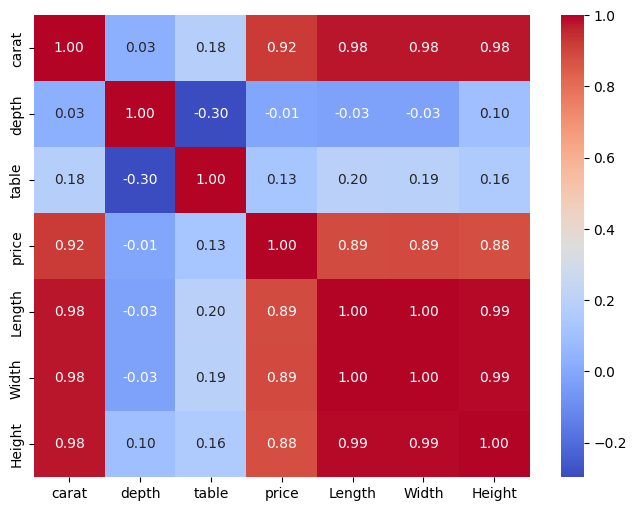

In [91]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.show()

In [92]:
cut_map = {'Fair': 1, 'Good': 2, 'Very Good': 3, 'Premium': 4, 'Ideal': 5}
color_map = {'J': 1, 'I': 2, 'H': 3, 'G': 4, 'F': 5, 'E': 6, 'D': 7}
clarity_map = {'I1': 1, 'SI2': 2, 'SI1': 3, 'VS2': 4, 'VS1': 5, 'VVS2': 6, 'VVS1': 7, 'IF': 8}

df['cut'] = df['cut'].map(cut_map)
df['color'] = df['color'].map(color_map)
df['clarity'] = df['clarity'].map(clarity_map)

df.head()

,carat,cut,color,clarity,depth,table,price,Length,Width,Height
0,0.23,5,6,2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,4,6,3,59.8,61.0,326,3.89,3.84,2.31
2,0.23,2,6,5,56.9,65.0,327,4.05,4.07,2.31
3,0.29,4,2,4,62.4,58.0,334,4.20,4.23,2.63
4,0.31,2,1,2,63.3,58.0,335,4.34,4.35,2.75


In [93]:
print(df[['cut', 'color', 'clarity']].isnull().sum())

cut        0
color      0
clarity    0
dtype: int64


In [94]:
from sklearn.model_selection import train_test_split

In [95]:
X = df.drop('price', axis=1)
y = df['price']

In [96]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [97]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(43017, 9)
(10755, 9)
(43017,)
(10755,)


In [101]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [ ]:
model = LinearRegression()

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [103]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [ ]:
y_pred = model.predict(X_test)

print("R2 score:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))

R2 score: 0.9048394337751376
MAE: 797.9082798782815
MSE: 1478169.7292132373
RMSE: 1215.8000366891083


In [104]:
from sklearn.tree import DecisionTreeRegressor

In [105]:
model_dt = DecisionTreeRegressor(random_state=42)

In [106]:
model_dt.fit(X_train, y_train)

,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_l

In [108]:
y_pred_dt = model_dt.predict(X_test)

In [110]:
print("R2 score:", r2_score(y_test, y_pred_dt))
print("MAE:", mean_absolute_error(y_test, y_pred_dt))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_dt)))
print("Train R2:", model_dt.score(X_train, y_train))
print("Test R2:", model_dt.score(X_test, y_test))

R2 score: 0.9659206601893902
MAE: 353.9905160390516
RMSE: 727.5774491357841
Train R2: 0.9999970383471052
Test R2: 0.9659206601893902


In [112]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Decision Tree'],
    'R2': [r2_score(y_test, y_pred), r2_score(y_test, y_pred_dt)],
    'MAE': [mean_absolute_error(y_test, y_pred), mean_absolute_error(y_test, y_pred_dt)],
    'RMSE': [np.sqrt(mean_squared_error(y_test, y_pred)),
             np.sqrt(mean_squared_error(y_test, y_pred_dt))],
}).round(3)
print(results)



               Model     R2      MAE      RMSE
0  Linear Regression  0.905  797.908  1215.800
1      Decision Tree  0.966  353.991   727.577


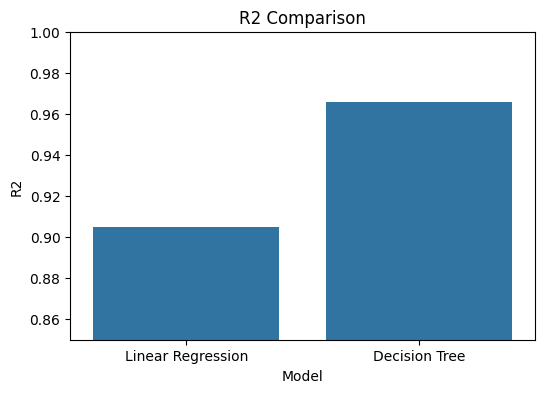

In [113]:
plt.figure(figsize=(6, 4))
sns.barplot(x='Model', y='R2', data=results)
plt.ylim(0.85, 1)
plt.title('R2 Comparison')
plt.show()

carat      0.627889
Width      0.260030
clarity    0.062643
color      0.033154
Height     0.005159
Length     0.003941
depth      0.002906
table      0.002268
cut        0.002010
dtype: float64


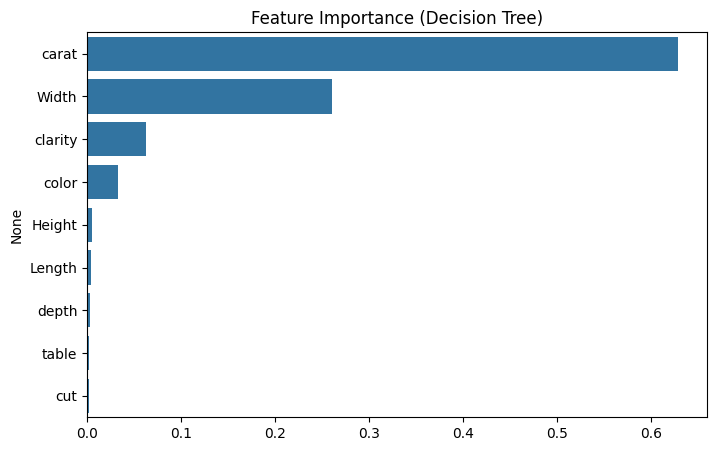

In [114]:
importance = pd.Series(model_dt.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importance)

plt.figure(figsize=(8, 5))
sns.barplot(x=importance.values, y=importance.index)
plt.title('Feature Importance (Decision Tree)')
plt.show()

In [116]:
row = X_test.iloc[[0]]

print("Actual:", y_test.iloc[0])
print("Linear:", model.predict(row)[0])
print("Tree:  ", model_dt.predict(row)[0])

Actual: 4039
Linear: 4123.845275802487
Tree:   3276.0


In [117]:
print("Linear Regression accuracy:", round(model.score(X_test, y_test) * 100, 2), "%")
print("Decision Tree accuracy:    ", round(model_dt.score(X_test, y_test) * 100, 2), "%")

Linear Regression accuracy: 90.48 %
Decision Tree accuracy:     96.59 %
